# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Marana, Kyle
- _Student No._: 2024-14996
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures
![A](fig1.png)
**Figure 1. Synthetic data interpolation.** Randomly sampled sine data (purple) reconstructed with linear, nearest, previous, next, quadratic, and cubic interpolation, compared against the true sin(x) (black)
![A](fig2.png)
**Figure 2. Real-world data reconstruction.** Dow Jones series reconstructed from 50%, 30%, 10%, and 5% using each interpolation method

### Report discussion

**Interpolator comparison:** Nearest, previous, and next give staircase curves with large jumps wherever samples are sparse. Linear is continuous but cuts the peaks and troughs. Quadratic and cubic are nearly indistinguishable from $sin(x)$, since a smooth function suits polynomial pieces, cubic is the most accurate.

**Sampling-level comparison:** Down to 30%, all methods track the Dow series well. At 10% and 5%, short-lived fluctuations vanish, and quadratic and cubic overshoots and oscillations near sharp changes (e.g., above 15,000 near index 350 at 5%). Interpolators are only valid inside the sampled range, so the endpoints were forced into the sample, extrapolating beyond it is unreliable.

### Other comments
- God, it's brutal out here - Olivia Rodrigo, 2021

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)


### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

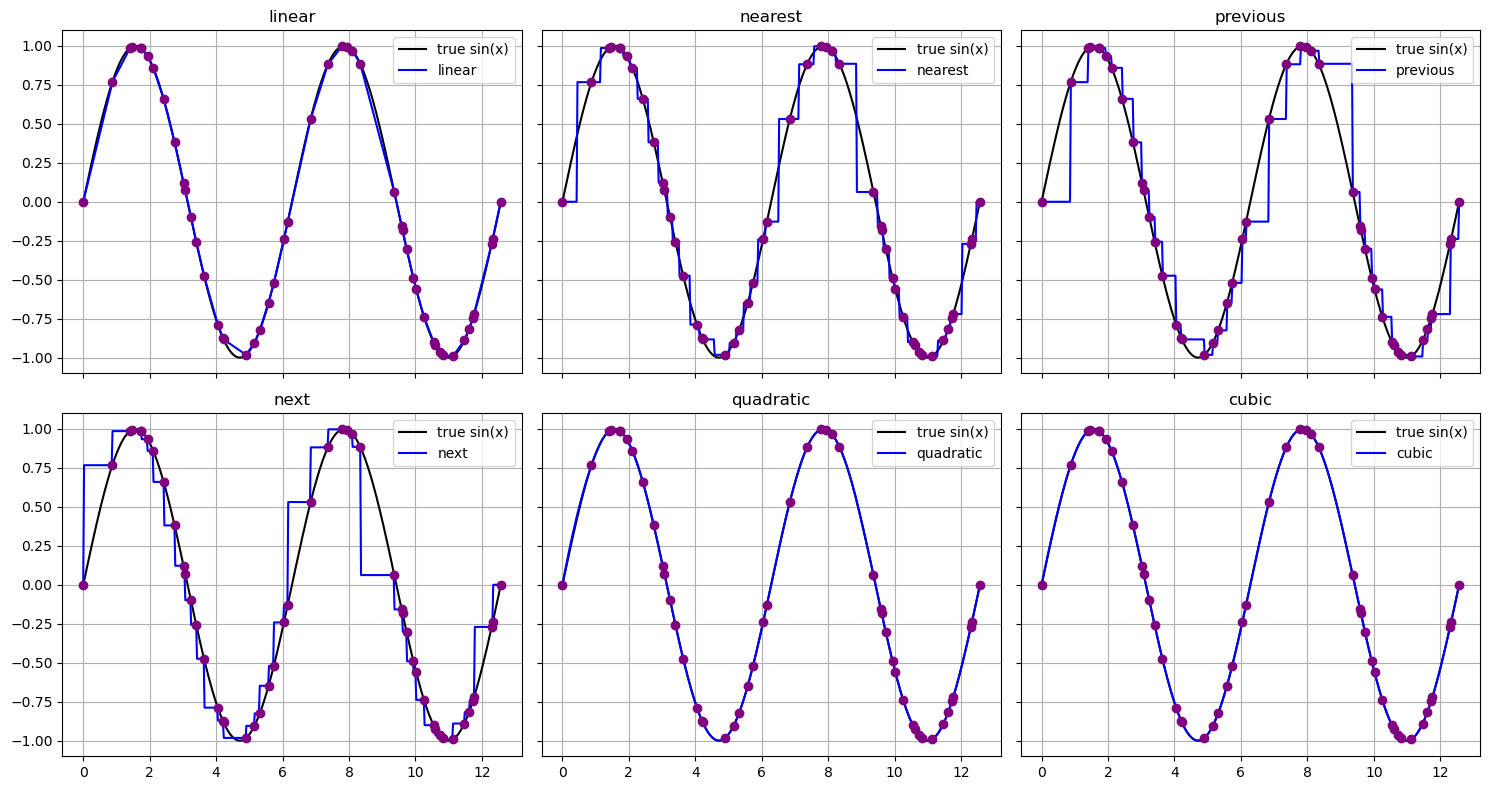

In [13]:
import scipy.interpolate

kinds = ['linear', 'nearest', 'previous', 'next', 'quadratic', 'cubic'] # so that i wont need to plot them individually resulting in a much shorter code using zip and axes.ravel
samplen = 50
samplel= 500

x_fine = np.linspace(0, 4.0001*np.pi, samplel)
x_s = np.sort(rng.uniform(0, 4.0001*np.pi,samplen))
x_s[0], x_s[-1] = 0, 4.0001*np.pi # forces the sin function to be the endpoints of the range 0 to 4.0001pi and 4.0001pi cuz why not
y_s = np.sin(x_s)

# plotting the graphs
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, kind in zip(axes.ravel(), kinds):
    f = scipy.interpolate.interp1d(x_s, y_s, kind=kind)
    ax.plot(x_fine, np.sin(x_fine), 'k-', label='true sin(x)')
    ax.plot(x_fine, f(x_fine), 'blue', label=kind)
    ax.scatter(x_s, y_s, c='purple', zorder=3)
    ax.set_title(kind)
    ax.legend(loc='upper right')
    ax.grid()
plt.savefig("fig1.png")
plt.tight_layout(); plt.show()


### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [10]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

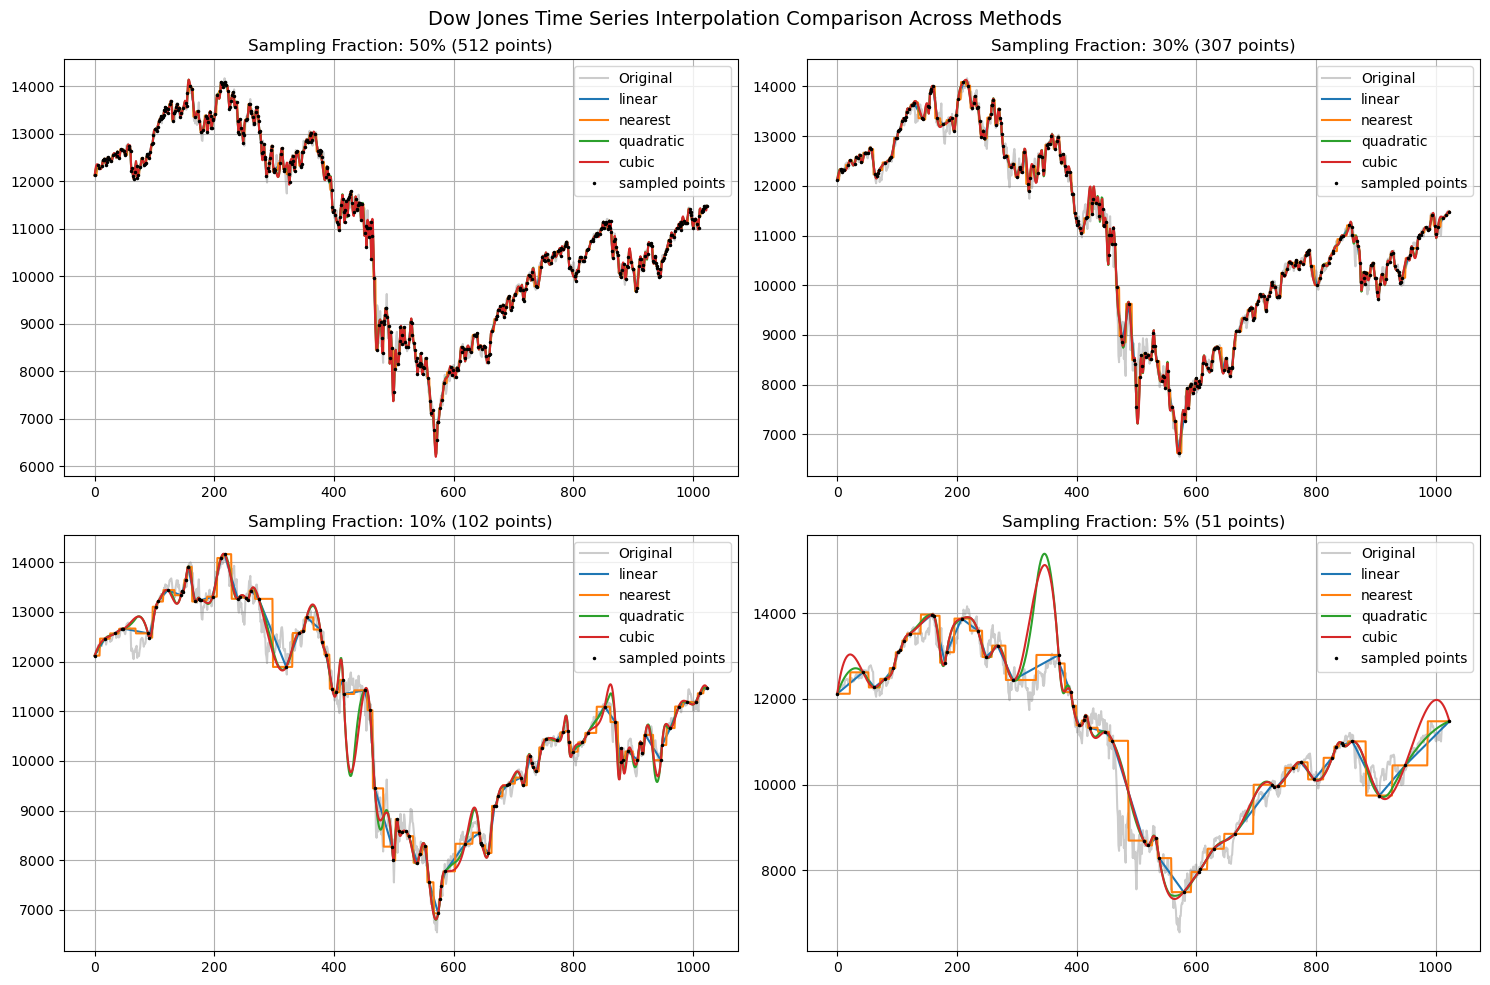

In [16]:
data = np.loadtxt("dow.txt")
x_full = np.arange(len(data))
y_full = data

rng = np.random.default_rng(42)

# configurations for looping
fractions = [0.50, 0.30, 0.10, 0.05]
methods = ['linear', 'nearest', 'quadratic', 'cubic']

plt.figure(figsize=
           (15, 10))

# loop over each sampling fraction and create subplots
for i, frac in enumerate(fractions):
    # sample indices and enforce start or end boundaries
    idx = np.sort(rng.choice(len(data), size=int(len(data)*frac), replace=False))
    idx[0], idx[-1] = 0, len(data) - 1

    plt.subplot(2, 2, i+1)
    plt.plot(x_full, y_full, color='gray', alpha=0.4, label='Original')

    # loop over each interpolation method
    for method in methods:
        f_interp = interpolate.interp1d(x_full[idx], y_full[idx], kind=method)
        plt.plot(x_full, f_interp(x_full), label=method)
    # shows the sparse sample points used for fitting
    plt.plot(x_full[idx], y_full[idx], 'k.', markersize=3, label='sampled points')
    plt.title(f'Sampling Fraction: {int(frac*100)}% ({len(idx)} points)')
    plt.grid(True)
    plt.legend()

plt.suptitle('Dow Jones Time Series Interpolation Comparison Across Methods', fontsize=14)
plt.tight_layout()
plt.savefig("fig2.png")
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

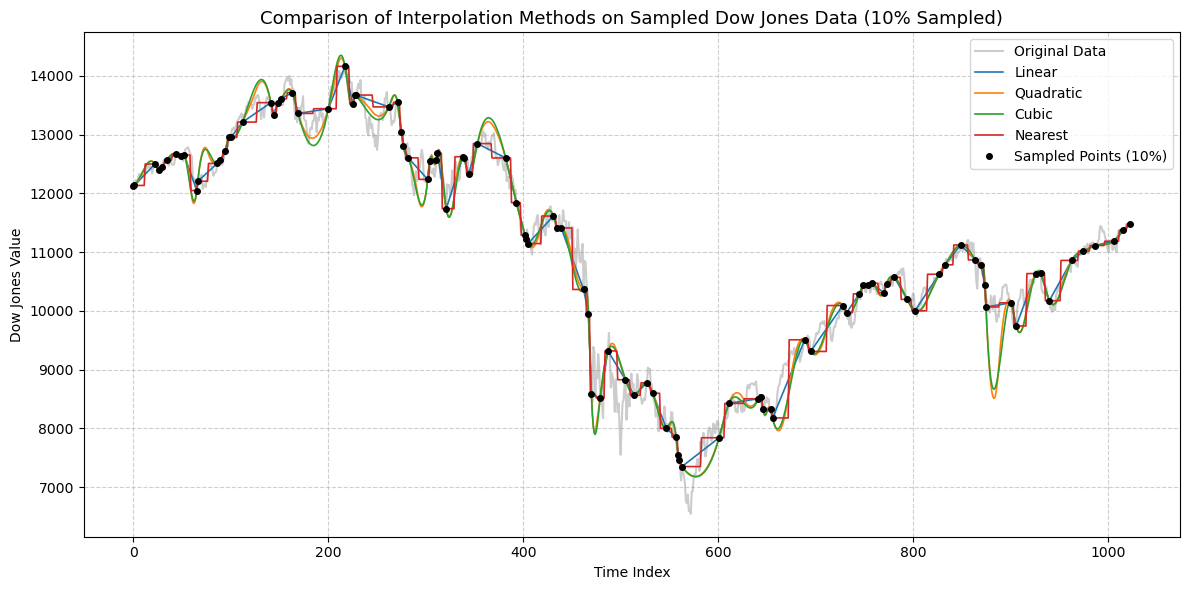

In [15]:
# selects 10% sample subset randomly with no replacement
sampled_idx = np.sort(rng.choice(len(data), size=int(len(data)*0.10), replace=False))

sampled_idx[0], sampled_idx[-1] = 0, len(data) - 1

# extract x and y coordinates corresponding to the sampled subset
x_sample, y_sample = x_full[sampled_idx], y_full[sampled_idx]


# plotting full time series
plt.figure(figsize=(12, 6))
plt.plot(x_full, y_full, color='gray', alpha=0.4, linewidth=1.5, label='Original Data')

# fit and reconstruct the full series using interpolation methods
for method in ['linear', 'quadratic', 'cubic', 'nearest']:
    f_interp = interpolate.interp1d(x_sample, y_sample, kind=method)
    plt.plot(x_full, f_interp(x_full), label=method.capitalize(), linewidth=1.2)

# plotting and overlaying the 10% sample points used for model fititng
plt.plot(x_sample, y_sample, 'ko', markersize=4,label='Sampled Points (10%)')
plt.title('Comparison of Interpolation Methods on Sampled Dow Jones Data (10% Sampled)', fontsize=13)
plt.xlabel('Time Index')
plt.ylabel('Dow Jones Value')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("fig3.png")
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.



---

The code reconstructs a known sine function and the Dow Jones series from randomly sampled points using scipy’s `interp1d`, looping over interpolation kinds and sampling fractions so each comparison takes a few lines instead of repeated code. Endpoints are forced into every sample so all query points lie inside the interpolation domain (`interp1d` raises an error on extrapolation), and a seeded random generator keeps results reproducible. Problem 3 isolates the 10% case to show how higher-order methods overshoot on sparse, rapidly changing data.